# CS540 Homework 3 Q3
Authors: Group 9: David Heald, Jackson Madsen, Vlad Maliutin

Date: 10/16/2026

In this notebook we use the SMS spam dataset (no header row) to look at ham vs spam messages, find the most common words in each class, and then train three classifiers (Naive Bayes, Logistic Regression, and a linear SVM) using TF-IDF features.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

## Part 1 – Load the dataset

In [2]:
df = pd.read_csv("data/sms_spam_no_header.csv", header=None, names=["label", "message"])
print("Shape:", df.shape)
df.head()

Shape: (5574, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


### Number of messages per class

In [3]:
counts = df["label"].value_counts()
print(counts)
print()
print("Percent spam: {:.1f}%".format(counts["spam"] / len(df) * 100))

label
ham     4827
spam     747
Name: count, dtype: int64

Percent spam: 13.4%


### Average message length per class (characters)

In [4]:
df["length"] = df["message"].str.len()
avg_len = df.groupby("label")["length"].mean()
print(avg_len.round(2))

label
ham      71.44
spam    138.63
Name: length, dtype: float64


There are 4,827 ham messages and 747 spam messages (5,574 total), so the data is pretty imbalanced. Spam messages are also about twice as long on average (around 139 characters vs. about 71 for ham). This makes sense since spam usually tries to fit a lot of info like prizes, phone numbers and links into the message, while normal texts are short.

## Part 2 – Top 10 most frequent words (CountVectorizer)

In [5]:
def top_words(messages, n=10):
    cv = CountVectorizer(stop_words="english")
    X = cv.fit_transform(messages)
    word_counts = X.sum(axis=0).A1
    words = pd.Series(word_counts, index=cv.get_feature_names_out())
    return words.sort_values(ascending=False).head(n)

ham_top = top_words(df[df["label"] == "ham"]["message"])
spam_top = top_words(df[df["label"] == "spam"]["message"])

print("Top 10 ham words:")
print(ham_top)
print()
print("Top 10 spam words:")
print(spam_top)

Top 10 ham words:
gt      318
lt      316
just    297
ok      288
ll      266
ur      247
know    237
good    235
like    234
got     233
dtype: int64

Top 10 spam words:
free      224
txt       163
ur        144
mobile    127
text      125
stop      123
claim     113
reply     104
www        98
prize      93
dtype: int64


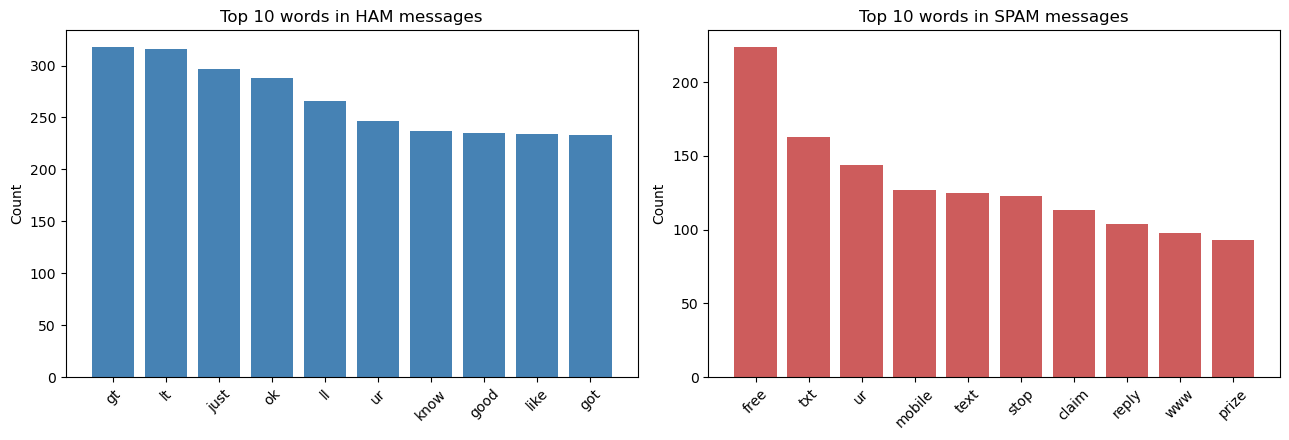

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(ham_top.index, ham_top.values, color="steelblue")
axes[0].set_title("Top 10 words in HAM messages")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis="x", rotation=45)

axes[1].bar(spam_top.index, spam_top.values, color="indianred")
axes[1].set_title("Top 10 words in SPAM messages")
axes[1].set_ylabel("Count")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

The ham words are casual everyday texting words (like "just", "ok", "ll", "ur", "know", "got") and a lot of them are abbreviations. The spam words are very different, things like "free", "txt", "mobile", "claim", "prize", "reply" and "stop".

## Part 3 – TF-IDF and classifiers

First we split the data 70/30 into train and test. We used `stratify` so both sets keep the same ham/spam ratio, and `random_state=42`. The TF-IDF vectorizer is fit only on the training data and then used to transform the test data, so no information from the test set leaks into training.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    df["message"], df["label"], test_size=0.3, random_state=42, stratify=df["label"]
)

tfidf = TfidfVectorizer(stop_words="english")
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Train size:", X_train_tfidf.shape)
print("Test size:", X_test_tfidf.shape)

Train size: (3901, 6917)
Test size: (1673, 6917)


### Train and evaluate the three models

In [8]:
models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Linear SVM": LinearSVC(),
}

results = []

for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    y_pred = model.predict(X_test_tfidf)

    print("=" * 55)
    print(name)
    print("=" * 55)
    print("Accuracy: {:.4f}".format(accuracy_score(y_test, y_pred)))
    print(classification_report(y_test, y_pred, digits=3))

    report = classification_report(y_test, y_pred, output_dict=True)
    results.append({
        "Model": name,
        "Accuracy": report["accuracy"],
        "Ham Precision": report["ham"]["precision"],
        "Ham Recall": report["ham"]["recall"],
        "Ham F1": report["ham"]["f1-score"],
        "Spam Precision": report["spam"]["precision"],
        "Spam Recall": report["spam"]["recall"],
        "Spam F1": report["spam"]["f1-score"],
    })

Multinomial Naive Bayes
Accuracy: 0.9731
              precision    recall  f1-score   support

         ham      0.970     1.000     0.985      1449
        spam      1.000     0.799     0.888       224

    accuracy                          0.973      1673
   macro avg      0.985     0.900     0.937      1673
weighted avg      0.974     0.973     0.972      1673

Logistic Regression
Accuracy: 0.9689
              precision    recall  f1-score   support

         ham      0.966     0.999     0.982      1449
        spam      0.994     0.772     0.869       224

    accuracy                          0.969      1673
   macro avg      0.980     0.886     0.926      1673
weighted avg      0.970     0.969     0.967      1673

Linear SVM
Accuracy: 0.9868
              precision    recall  f1-score   support

         ham      0.986     0.999     0.992      1449
        spam      0.990     0.911     0.949       224

    accuracy                          0.987      1673
   macro avg      0.98

### Summary table

In [9]:
results_df = pd.DataFrame(results).set_index("Model").round(3)
results_df

,Accuracy,Ham Precision,Ham Recall,Ham F1,Spam Precision,Spam Recall,Spam F1
Model,,,,,,,
Multinomial Naive Bayes,0.973,0.970,1.000,0.985,1.000,0.799,0.888
Logistic Regression,0.969,0.966,0.999,0.982,0.994,0.772,0.869
Linear SVM,0.987,0.986,0.999,0.992,0.990,0.911,0.949


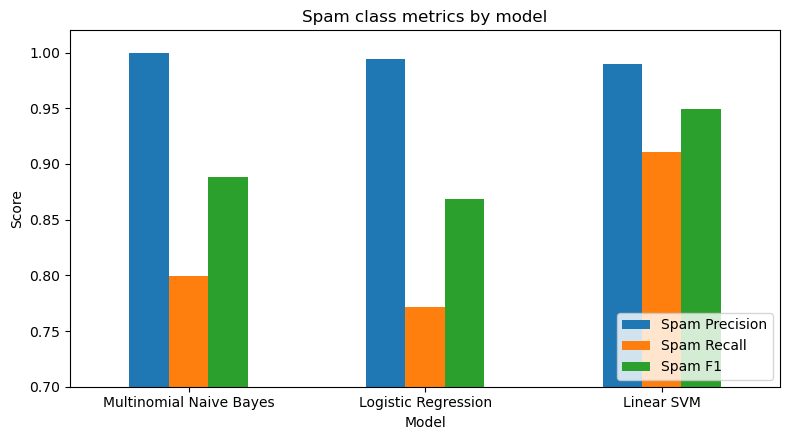

In [10]:
results_df[["Spam Precision", "Spam Recall", "Spam F1"]].plot(kind="bar", figsize=(8, 4.5), rot=0)
plt.title("Spam class metrics by model")
plt.ylim(0.7, 1.02)
plt.ylabel("Score")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Discussion – Which model is best for spam detection?

All three models get high accuracy (around 97–99%), but accuracy alone is a bit misleading here because about 87% of the messages are ham. A model that just said "ham" every time would already get 87%. So for spam detection We mostly looked at the spam precision, recall and F1-score.

- Ham class: all three models do very well on ham, with F1-scores above 0.98 and recall close to 1.0. Almost no real messages get marked as spam.
- Spam precision: all three are near perfect (0.99–1.00). When they say something is spam, they are almost always right. Naive Bayes actually got 1.00 precision, meaning zero false positives.
- Spam recall: this is where the models are different. Naive Bayes caught about 80% of spam and Logistic Regression about 77%, but the Linear SVM caught about 91%. So NB and LR let a lot more spam slip through.

The Linear SVM performs best for spam detection. It has the highest accuracy (about 98.7%), the highest spam recall (about 0.91) and the highest spam F1-score (about 0.95), while its spam precision is still around 0.99. In other words it catches a lot more spam without really increasing false alarms.

We think Naive Bayes and Logistic Regression have lower spam recall because the classes are imbalanced, so they are more "careful" about predicting spam. Naive Bayes would still be a decent choice since it is very fast and never flagged a real message as spam, which matters because losing a real text is worse than seeing a spam one.